<a href="https://colab.research.google.com/github/byAnree/AF2_IAM/blob/main/AF2_IAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AF 2: Modelos de Aprendizaje Supervisado - Introducción al Aprendizaje Máquina
2077734 - Renato López Trujillo

2121978 - Edgar Andree Noyola Rangel

2226630 - Arely Carrillo Sustaita

Red neuronal (Keras / TensorFlow) para predecir `stroke` a partir del dataset limpio de la Actividad Fundamental 1.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Semilla para que los resultados sean reproducibles
SEED = 42
keras.utils.set_random_seed(SEED)

## Carga del dataset limpio

In [2]:
ruta = "stroke_limpio.csv"
if not os.path.exists(ruta):
    # Si el archivo no está subido directamente a Colab, se busca en Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    ruta = "/content/drive/MyDrive/stroke_limpio.csv"

df = pd.read_csv(ruta)
print(df.shape)
print(df.dtypes.value_counts())   # todas las columnas deben ser numéricas
df.head()

(5110, 20)
int64      17
float64     3
Name: count, dtype: int64


,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,gender_Other,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,0,1,0,0,0,1,0,0
1,61.0,0,0,1,0,202.21,28.1,1,1,0,0,0,0,0,1,0,0,0,1,0
2,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0,0,0,0,1,0
3,49.0,0,0,1,1,171.23,34.4,1,1,0,0,0,0,1,0,0,0,0,0,1
4,79.0,1,0,1,0,174.12,24.0,1,1,0,0,0,0,0,1,0,0,0,1,0


## Sección 1: División de datos y escalado

In [3]:
X = df.drop("stroke", axis=1)
y = df["stroke"]
print("Distribución original de la variable objetivo:")
print(y.value_counts(normalize=True))

Distribución original de la variable objetivo:
stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print("Train:")
print(y_train.value_counts(normalize=True))
print("\nTest:")
print(y_test.value_counts(normalize=True))   # deben verse casi idénticas

Train:
stroke
0    0.951321
1    0.048679
Name: proportion, dtype: float64

Test:
stroke
0    0.951076
1    0.048924
Name: proportion, dtype: float64


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit SOLO con train
X_test_scaled = scaler.transform(X_test)         # solo transform en test

# Verificación: media ≈ 0 y desviación estándar = 1
print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

[-0. -0.  0.  0. -0.  0. -0. -0. -0.  0.  0. -0. -0. -0.  0.  0.  0. -0.
  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Sección 2: Diseño de la arquitectura

In [6]:
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation="relu"),      # capa oculta 1
    layers.Dense(16, activation="relu"),      # capa oculta 2
    layers.Dense(1, activation="sigmoid"),    # salida: probabilidad de stroke (0 a 1)
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

## Sección 3: Entrenamiento, métricas y optimizadores

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="auc"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.Precision(name="precision"),
    ],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=10,
    restore_best_weights=True,
)

# Peso para la clase minoritaria (compensa el desbalance)
neg, pos = np.bincount(y_train)
class_weight = {0: 1.0, 1: neg / pos}
print("class_weight:", class_weight)

class_weight: {0: 1.0, 1: np.float64(19.542713567839197)}


In [8]:
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    class_weight=class_weight,
    verbose=1,
)

Epoch 1/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - auc: 0.5464 - loss: 1.3208 - precision: 0.0390 - recall: 0.2368 - val_auc: 0.5813 - val_loss: 0.5790 - val_precision: 0.0559 - val_recall: 0.3404
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - auc: 0.7289 - loss: 1.1038 - precision: 0.0855 - recall: 0.7237 - val_auc: 0.7225 - val_loss: 0.5565 - val_precision: 0.0973 - val_recall: 0.7021
Epoch 3/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - auc: 0.8099 - loss: 1.0074 - precision: 0.1000 - recall: 0.8421 - val_auc: 0.7871 - val_loss: 0.5304 - val_precision: 0.1192 - val_recall: 0.7660
Epoch 4/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - auc: 0.8328 - loss: 0.9525 - precision: 0.1083 - recall: 0.8355 - val_auc: 0.8075 - val_loss: 0.5102 - val_precision: 0.1268 - val_recall: 0.7660
Epoch 5/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - auc: 0.8439 - loss: 0.9159 - precision: 0.1188 - recall: 0.8553 - val_auc: 0.8177 - val_loss: 0.4933 - val_precision: 0.1439 - val_recall: 0.

### Curvas de entrenamiento

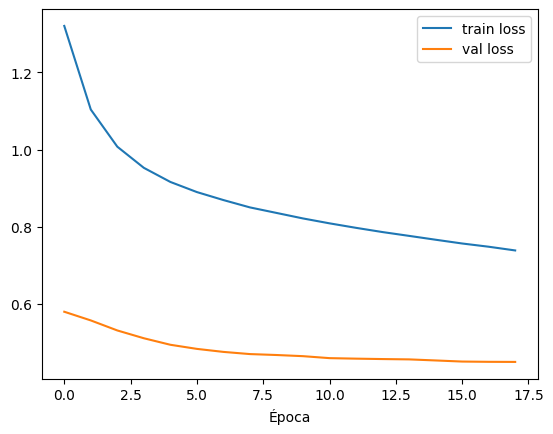

In [9]:
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Época")
plt.legend()
plt.show()

### Evaluación en el conjunto de prueba

In [10]:
resultados = model.evaluate(X_test_scaled, y_test, verbose=0, return_dict=True)
print(resultados)

y_prob = model.predict(X_test_scaled)
y_pred = (y_prob > 0.5).astype(int).ravel()

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

{'auc': 0.8164197206497192, 'loss': 0.4592853784561157, 'precision': 0.12624584138393402, 'recall': 0.7599999904632568}
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              precision    recall  f1-score   support

           0       0.98      0.73      0.84       972
           1       0.13      0.76      0.22        50

    accuracy                           0.73      1022
   macro avg       0.55      0.74      0.53      1022
weighted avg       0.94      0.73      0.81      1022

[[709 263]
 [ 12  38]]
